## Base de dados
Utilizamos o conjunto de dados *Telco Customer Churn*, disponível em https://www.kaggle.com/datasets/blastchar/telco-customer-churn. 

Esse *dataset* simula a base de clientes de uma empresa de telecomunicações. O objetivo principal do conjunto de dados é construir um modelo preditivo capaz de prever o *churn* — ou seja, identificar se um cliente está prestes a cancelar seus serviços (abandonar a empresa) no próximo mês.

O arquivo possui 7.043 linhas (cada uma representando um cliente único) e 21 colunas (características). A coluna "alvo" (a variável que os modelos tentam prever) se chama Churn e recebe os valores Yes (cancelou) ou No (não cancelou). As outras 20 colunas servem como as pistas para o modelo e podem ser divididas em três categorias principais:

<ins> **Informações Demográficas** </ins> 

- *gender*: Gênero do cliente (Masculino/Feminino).
- *SeniorCitizen*: Indica se o cliente é idoso (1) ou não (0).
- *Partner* e *Dependents*: Indica se o cliente tem um parceiro(a) e se possui dependentes (filhos, etc).

<ins> **Serviços Contratados** </ins>

Mostra os pacotes que o cliente assina, como: telefone (PhoneService), múltiplas linhas (MultipleLines), provedor de internet (InternetService - DSL, Fibra Óptica ou Não possui), segurança online (OnlineSecurity), suporte técnico (TechSupport), streaming de TV e filmes, entre outros.

<ins> **Informações da Conta do Cliente:** </ins>

- *tenure*: Há quantos meses o cliente está na empresa (uma variável fortíssima, já que clientes mais antigos tendem a ser mais fiéis).
- *Contract*: O tipo de contrato (mês a mês, 1 ano ou 2 anos).
- *PaymentMethod*: Forma de pagamento (cartão de crédito, cheque eletrônico, etc).
- *MonthlyCharges* e *TotalCharges*: O valor da mensalidade e o valor total que o cliente já gastou com a empresa ao longo do tempo.

## Carregando os dados
Primeiro passo: Importar o dataset *Telco Customer Churn* (IBM Sample, via Kaggle) e
verificar sua dimensão para confirmar que todos os registros e colunas
foram importados corretamente.

In [1]:
import pandas as pd

df = pd.read_csv('../data/Telco-Customer-Churn.csv')
df.shape

(7043, 21)

## Visão geral das colunas

Segundo passo: analisar as primeiras linhas e os tipos de dados de cada coluna para
entender a estrutura do dataset antes de qualquer tratamento.

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Depois, podemos obter as informações relacionadas ao *dataset*, como as colunas e os tipos de dados:

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Correção de tipo: TotalCharges

A coluna `TotalCharges` foi importada como texto (`str`) em vez de
numérica.
É neessário converter com `pd.to_numeric` (valores inválidos viram `NaN`) e
verificar quantos registros foram afetados.

In [13]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].isnull().sum()

np.int64(11)

## Investigação dos valores nulos em TotalCharges

Verificar se os 11 registros nulos possuem relaçao com clientes com `tenure = 0`
(clientes recém-chegados que ainda não geraram cobrança total).

In [14]:
df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges']]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


## Tratamento dos valores nulos

Confirmado: os 11 registros nulos em `TotalCharges` correspondem a clientes
com `tenure = 0` (cliente que contratou a operadora tem menos de um mês, ou seja, ainda não completaram um ciclo de cobrança). Usar a função `fillna()` para substituir todo `NaN` da coluna por `0`, refletindo assim a realidade desses clientes.

In [15]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].isnull().sum()

np.int64(0)

## Distribuição da variável alvo (Churn)

Verificar a proporção entre clientes que cancelaram e os que não cancelaram.

In [16]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

## Distribuição das variáveis numéricas

Visualizar a distribuição de `tenure`, `MonthlyCharges` e `TotalCharges`
para entender melhor a forma dos dados (concentração, assimetria, possíveis
outliers) antes de começar a  modelagem.

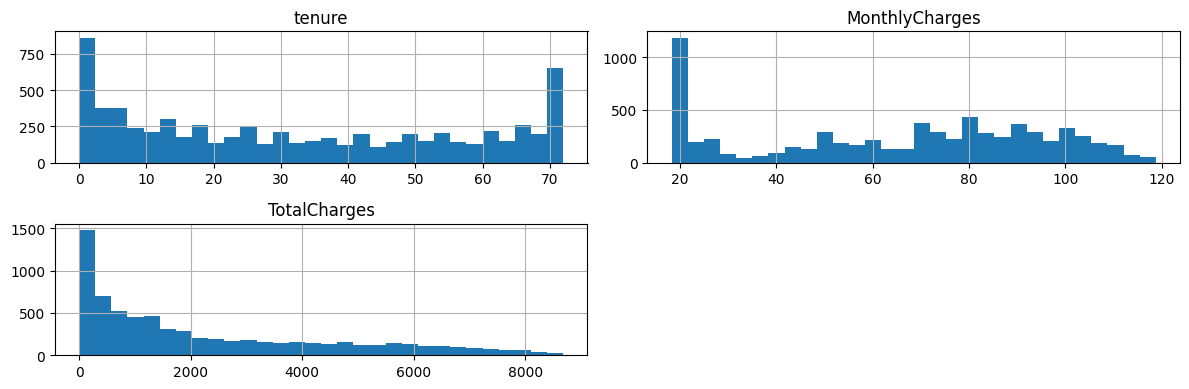

In [17]:
import matplotlib.pyplot as plt

df[['tenure', 'MonthlyCharges', 'TotalCharges']].hist(figsize=(12, 4), bins=30)
plt.tight_layout()
plt.show()

## Churn por variável categórica (visão geral)

Criar as faixas de tenure e analisar a taxa de churn de todas as
variáveis categóricas relevantes,
para identificar rapidamente quais têm maior diferença de churn entre
categorias.

In [7]:
df['tenure_faixa'] = pd.cut(df['tenure'], bins=[0, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])

categoricas = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure_faixa',
               'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
               'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
               'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

for col in categoricas:
    print(f"\n--- {col} ---")
    print(df.groupby(col, observed=True)['Churn'].value_counts(normalize=True).unstack()['Yes'].sort_values(ascending=False))


--- gender ---
gender
Female    0.269209
Male      0.261603
Name: Yes, dtype: float64

--- SeniorCitizen ---
SeniorCitizen
1    0.416813
0    0.236062
Name: Yes, dtype: float64

--- Partner ---
Partner
No     0.329580
Yes    0.196649
Name: Yes, dtype: float64

--- Dependents ---
Dependents
No     0.312791
Yes    0.154502
Name: Yes, dtype: float64

--- tenure_faixa ---
tenure_faixa
0-12     0.476782
13-24    0.287109
25-48    0.203890
49-72    0.095132
Name: Yes, dtype: float64

--- PhoneService ---
PhoneService
Yes    0.267096
No     0.249267
Name: Yes, dtype: float64

--- MultipleLines ---
MultipleLines
Yes                 0.286099
No                  0.250442
No phone service    0.249267
Name: Yes, dtype: float64

--- InternetService ---
InternetService
Fiber optic    0.418928
DSL            0.189591
No             0.074050
Name: Yes, dtype: float64

--- OnlineSecurity ---
OnlineSecurity
No                     0.417667
Yes                    0.146112
No internet service    0.074050


## Churn por Contract, PaymentMethod e InternetService

Visualizar as três variáveis que possuem maior diferença de churn entre
categorias, identificadas na análise geral anterior.

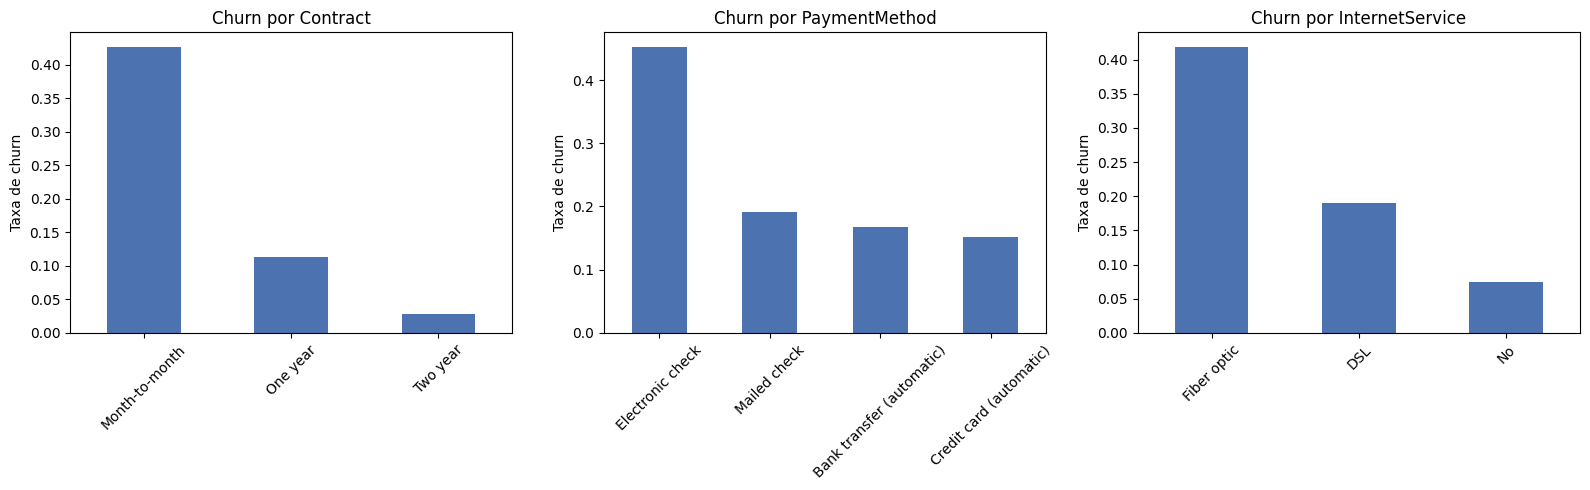

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['Contract', 'PaymentMethod', 'InternetService']):
    taxa = df.groupby(col, observed=True)['Churn'].value_counts(normalize=True).unstack()['Yes'].sort_values(ascending=False)
    taxa.plot(kind='bar', ax=ax, color='#4C72B0')
    ax.set_title(f'Churn por {col}')
    ax.set_ylabel('Taxa de churn')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Correlação entre variáveis numéricas

Verificar a correlação entre tenure, MonthlyCharges e TotalCharges, para
confirmar que TotalCharges é redundante com as outras duas (já que é
praticamente o produto delas acumulado).

In [8]:
df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr()

,tenure,MonthlyCharges,TotalCharges
tenure,1.00000,0.247900,0.825880
MonthlyCharges,0.24790,1.000000,0.651065
TotalCharges,0.82588,0.651065,1.000000


# Conclusão da EDA

A análise exploratória confirma que o churn tem padrões claros e
explicáveis, úteis tanto para o modelo quanto para ação de negócio
imediata:

**Principais drivers de churn identificados:**
1. **Tipo de contrato** é o fator mais forte — clientes mensais cancelam
   15x mais que os de contrato de 2 anos.
2. **Tempo de casa (tenure)** tem relação quase linear — clientes nos
   primeiros 12 meses cancelam 5x mais que os com 49-72 meses,
   reforçando a importância de reter o cliente logo no início.
3. **Tipo de internet**: clientes com fibra ótica têm *churn*
   surpreendentemente alto, o que pode indicar problema de
   preço, qualidade de serviço ou concorrência nesse segmento.
4. **Forma de pagamento**: cheque eletrônico concentra churn bem acima
   da média, sugerindo um
   perfil de cliente menos engajado digitalmente.

**Implicações para a modelagem (Etapa 2):**
- O dataset é desbalanceado (73,5% / 26,5%), o que reforça a decisão 
de usar recall/F1 em vez de acurácia como métrica principal.
- `TotalCharges` é altamente correlacionada com `tenure` (0,83) e pode
  ser redundante.
- As variáveis de add-on (OnlineSecurity, TechSupport, etc.) seguem o
  mesmo padrão de InternetService, sugerindo possível redundância entre
  elas.
- `gender` e `PhoneService` não mostraram relação relevante com churn e
  são candidatas a serem descartadas do modelo.

## Preparação para o baseline

Tirar colunas que não
agregam (customerID, tenure_faixa que já cumpriu seu papel), separar o
alvo e converter as categóricas pra número.

In [18]:
from sklearn.preprocessing import LabelEncoder

df_model = df.drop(columns=['customerID', 'tenure_faixa'])

df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})

categoricas_restantes = df_model.select_dtypes(include=['object', 'str']).columns

le = LabelEncoder()
for col in categoricas_restantes:
    df_model[col] = le.fit_transform(df_model[col])

df_model.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


## Treino do baseline

Separar treino/teste com estratificação (para manter a proporção de
*churn* em ambos os lados, já que é desbalanceado) e treinar com a Regressão Logística (*Scikit-Learn*).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Isola as variáveis previsoras (features) na matriz 'X', removendo a coluna alvo 'Churn' do dataframe.
X = df_model.drop(columns=['Churn'])
# Isola a variável alvo (target) no vetor 'y', contendo exatamente o que o modelo precisará prever ('Churn').
y = df_model['Churn']

# Divide os dados: 80% para treino e 20% para teste (test_size=0.2).
# O parâmetro 'stratify=y' garante que a proporção original de cancelamentos (Churn) seja mantida igual nas duas divisões.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1109)


# Inicializa o modelo matemático de Regressão Logística (LogisticRegression) para prever a probabilidade de cancelamento (Churn). 
# 'max_iter=1000' permite que o algoritmo faça até mil iterações para encontrar a solução matemática sem estourar o limite padrão.
model = LogisticRegression(max_iter=1000, random_state=1109)

# Executa o treinamento: o modelo analisa as características do cliente (X_train) e aprende os padrões que levam ao cancelamento (y_train).
model.fit(X_train, y_train)

# Avaliação final: o 'model.predict(X_test)' tenta adivinhar o churn usando apenas as informações dos clientes separados para teste.
# Em seguida, compara as previsões feitas com as respostas reais (y_test) e imprime o boletim de notas final.
print(classification_report(y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.67      0.55      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



C:\Users\Lucca Eugênio\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


<ins> Classe 0 (Não Cancelou):</ins>
O modelo apresenta uma precisão (precision) de 0.85 e consegue identificar corretamente 90% (recall) de todos os clientes fiéis à empresa, desempenho nesta categoria parece robusto. 

<ins> Classe 1 (Cancelou - *Churn*):</ins>
Esta é a classe crítica para o negócio, mas apresenta resultados mais fracos. Quando o algoritmo prevê que um cliente vai cancelar, acerta apenas 67% das vezes. O problema principal é a métrica "*recall*" de 0.55, o que significa que o modelo deixa escapar 45% dos clientes que efetivamente abandonam a empresa.   

<ins> *Accuracy* (Exatidão):</ins>
O modelo acerta 81% de todas as previsões globais, mas este valor mascara a falha na classe 1 devido ao forte desequilíbrio dos dados originais. 

<ins> *Support* (Amostra):</ins>
A métrica "*support*" mostra exatamente a raiz do desequilíbrio: no seu conjunto de teste, existem 1035 clientes que não cancelaram contra apenas 374 que cancelaram.   Para elevar a capacidade de retenção e melhorar o *"recall"* de 0.55, será necessário testar abordagens para dados desequilibrados, tais como aplicar técnicas de balanceamento (como SMOTE) ou ajustar os pesos das classes (*class_weight='balanced'*) no modelo.

## Correção do *warning* e tentativa de melhorar o *recall*

Variáveis numéricas em escalas muito diferentes (*tenure* até 72,
*TotalCharges* até 8000+) atrapalham a regressão logística. Padronizar
com *StandardScaler* antes de retreinar, deve resolver o *warning* e pode
ajudar o *recall* da classe 1, que é o que importa aqui.

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, random_state=1109)
model.fit(X_train_scaled, y_train)

print(classification_report(y_test, model.predict(X_test_scaled)))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.67      0.55      0.60       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



## Aplicação de mais peso à classe minoritária

O modelo está sendo conservador demais em apontar *churn*, isso por causa do
desbalanceamento. Usar class_weight='balanced', pois o sklearn penaliza mais
o erro na classe minoritária durante o treino, em vez de mexer no
*threshold* manualmente.

In [21]:
model = LogisticRegression(max_iter=1000, random_state=1109, class_weight='balanced')
model.fit(X_train_scaled, y_train)

print(classification_report(y_test, model.predict(X_test_scaled)))

              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.51      0.80      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



## Conclusão do *baseline*

Regressão logística simples, sem balanceamento, já convergia mas tinha
*recall* fraco na classe de interesse (0,55) — deixava passar quase metade dos
clientes que realmente cancelam, o pior erro possível segundo o ML Canvas.

A inclusão do parâmetro *class_weight='balanced'* alterou significativamente o comportamento preditivo do algoritmo, subiu pra 0,80, com queda
esperada na *precision* (0,51) e na acurácia geral (0,75), ou seja, forçou a regressão logística a penalizar mais os erros na classe minoritária e a assumir uma postura menos conservadora.   
- <ins> Aumento no Recall do *Churn* (Classe 1):</ins> A capacidade de identificar os cancelamentos reais subiu substancialmente para 80% (recall de 0.80). O modelo consegue agora detetar a grande maioria dos clientes que efetivamente abandonam a empresa.   
- <ins>Queda na Precisão (Classe 1):</ins> O compromisso (*trade-off*) para capturar mais cancelamentos foi a redução da precisão para 0.51. Dos clientes que o sistema agora classifica como propensos ao churn, apenas cerca de metade acaba realmente por cancelar, o que representa um aumento acentuado de falsos positivos.   
- <ins>Impacto Global:</ins> A exatidão geral (*accuracy*) desceu para 75%. O *recall* da classe 0 (clientes que não cancelaram) recuou para 0.73, refletindo a quantidade de clientes fiéis que o modelo passou a sinalizar incorretamente como estando em risco.   

Em contextos de negócio focados na retenção, esta matriz de resultados é frequentemente preferível à versão desbalanceada, assumindo que o custo financeiro de oferecer um incentivo de retenção a um cliente que não ia cancelar (falso positivo) é inferior ao impacto de perder a receita de um cliente insatisfeito (falso negativo).